# Dezvoltare software analiza date
## Tema 1 - Diferențe regionale în Uniunea Europeană

În această temă lucrați cu date reale **Eurostat** la nivel de regiune **NUTS2** (244 de regiuni din cele 27 de state membre). Folosiți ce am făcut la seminarii: selecție și filtrare, valori lipsă, `merge`/`join`, `groupby` + `agg`/`transform`, medii ponderate (seminarul 3), calcul matriceal cu `numpy` (seminarul 4) și grafice `matplotlib`.

**Anul de referință: 2023.**

### Datele (`data_in/`)

`Indicatori.csv` conține câte o linie pentru fiecare regiune NUTS2 (`Cod`, de exemplu `RO32`) și următorii indicatori, pentru anul 2023:

| Coloană | Indicator | Unitate |
|---|---|---|
| `PIB` | PIB pe locuitor | PPS (standard al puterii de cumpărare) |
| `Somaj` | Rata șomajului, 15-74 ani | % |
| `SperantaViata` | Speranța de viață la naștere | ani |
| `Tertiar` | Populația 25-64 ani cu studii superioare | % |
| `Populatie` | Populația la 1 ianuarie | persoane |
| `CD` | Cheltuieli de cercetare-dezvoltare | % din PIB |

Unele valori lipsesc (celule goale).

| Fișier | Coloane |
|---|---|
| `NUTS2.csv` | `Cod`, `Denumire` (denumirea regiunii) |
| `Tari.csv` | `CodTara`, `Tara`, `AnAderare`, `Euro` (1 = zona euro) |

Codul de țară este format din primele două litere ale codului regiunii (`RO32` → `RO`). Grecia are codul `EL`.

*Sursa datelor: Eurostat*

### Ce predați
- notebook-ul rulat complet (`Restart & Run All`), fără erori;
- folderul `data_out/` cu fișierele `Cerinta1.csv` ... `Cerinta9.csv` și cele 3 imagini de la cerința 10;
- după fiecare cerință, celula **Interpretare** completată cu 2-3 propoziții **scrise de voi**: ce arată rezultatul, nu ce face codul.

### Punctaj
Cerințele 1-9: câte 8 puncte (5 pentru cod și fișier, 3 pentru interpretare). Cerința 10: 28 de puncte (3 × 6 pentru grafice, 10 pentru concluzie). Total: 100 de puncte.

*Atenție:* cerințele se bazează una pe alta. Dacă vă blocați la una, salvați un rezultat parțial și mergeți mai departe.

In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.spatial.distance import cdist

Path("./data_out").mkdir(exist_ok=True)

## Cerința 1 - Citirea și combinarea datelor

Citiți cele trei fișiere și construiți un singur tabel cu câte o linie pentru fiecare regiune (index `Cod`), care să conțină indicatorii, denumirea regiunii, codul țării și informațiile despre țară. Salvați tabelul în *Cerinta1.csv*.

Afișați apoi numărul de valori lipsă pentru fiecare indicator și regiunile care au cel puțin o valoare lipsă.

**Verificare:** tabelul are 244 de linii, iar fiecare regiune are o denumire și o țară.

In [64]:
#citire din fisier
indicatori_df=pd.read_csv('./data_in/Indicatori.csv', index_col=0)
nuts2_df=pd.read_csv('./data_in/NUTS2.csv', index_col=0)
tari_df=pd.read_csv('./data_in/Tari.csv', index_col=0)

#construire tabel
tabel = indicatori_df.join(nuts2_df)
tabel["CodTara"] = tabel.index.str[:2]
tabel = tabel.join(tari_df, on=["CodTara"])

#salvare in csv
tabel.to_csv("./data_out/Cerinta1.csv")

#afisare valori lipsa
indicatori = ["PIB", "Somaj", "SperantaViata", "Tertiar", "Populatie", "CD"]
display(tabel[indicatori].isna().sum())

# afisare regiuni cu cu cel putin o valoare lipsa
regiuni_lipsa = tabel[tabel[indicatori].isna().any(axis=1)]
display(regiuni_lipsa)

# verificare!
print("Numar total de regiuni:")
print(len(tabel))

PIB               0
Somaj             5
SperantaViata     0
Tertiar           1
Populatie         0
CD               17
dtype: int64

,PIB,Somaj,SperantaViata,Tertiar,Populatie,CD,Denumire,CodTara,Tara,AnAderare,Euro
Cod,,,,,,,,,,,
DE22,44500,NaN,80.9,26.0,1244102,0.70,Niederbayern,DE,Germania,1958,1
DEB2,34400,NaN,80.9,29.2,524876,3.19,Trier,DE,Germania,1958,1
FRY1,25300,18.6,80.3,27.5,413861,NaN,Guadeloupe,FR,Franta,1958,1
FRY2,26200,10.8,81.6,29.2,359202,NaN,Martinique,FR,Franta,1958,1
FRY3,16300,14.0,79.4,23.7,290110,NaN,Guyane,FR,Franta,1958,1
FRY4,24600,19.0,82.1,24.4,886453,NaN,La Réunion,FR,Franta,1958,1
FRY5,11000,NaN,75.0,NaN,310199,NaN,Mayotte,FR,Franta,1958,1
NL11,46100,4.2,80.7,43.9,596075,NaN,Groningen,NL,Olanda,1958,1
NL12,36900,4.0,81.8,37.4,659551,NaN,Friesland (NL),NL,Olanda,1958,1


Numar total de regiuni:
244


**Interpretare:** Au fost analizati indicatori pentru cele 244 de regiuni ce au date raportate pentru anul 2023. Indicatorii PIB, Speranta de viata si populatia nu au valori lipsa pentru niciuna din regiuni, in timp ce indicatorii Somaj, tertiar si CD au valori lipsa. Majoritatea valorilor lipsa la CD sunt din Olanda(NL), iar restul datelor de la CD lipsesc de la regiuni ale Frantei(FR). Datele despre somaj lipsesc de la mai multe regiuni, nu se poate observa o tendinta.

## Cerința 2 - Tratarea valorilor lipsă

Înlocuiți fiecare valoare lipsă cu **media indicatorului în țara respectivă**. Dacă indicatorul lipsește pentru toată țara, folosiți media pe UE. Salvați rezultatul în *Cerinta2.csv*.

**Verificare:** după completare nu mai există valori lipsă.

*Întrebare:* de ce este mai potrivită media țării decât media UE? Pentru care țară nu a fost posibil acest lucru?

In [65]:
#tabel
tabel2 = tabel.copy()

#inlocuire cu media tarii
for i in indicatori:
    tabel2[i] = tabel2[i].fillna(tabel2.groupby("CodTara")[i].transform("mean"))

#inlocuire cu media ue
for i in indicatori:
    tabel2[i] = tabel2[i].fillna(tabel2[i].mean())

#salvare in fisier
tabel2.to_csv("./data_out/Cerinta2.csv")

#verificare!!!
print("Valori lipsa:", tabel2[indicatori].isna().sum().sum())

Valori lipsa: 0


**Interpretare:** Este mai potrivit sa introducem media pe tara in loc de media UE in locurile in care indicatorii nu au valori deoarece indicatorii sunt legati intre ei si fiecare regiune are situatii diferite. Astfel, folosind media tarii, valoarea folosita pentru un indicator este mai aproape de realitate. Singura tara pentru care inlocuirea cu media pe tara nu a fost posibila este Olanda, deoarece lipsesc complet datele pentru indicatorul CD, deci este necesara folosirea mediei UE.

## Cerința 3 - Profilul fiecărei țări

Pentru fiecare țară calculați: numărul de regiuni, PIB-ul mediu, minim și maxim, precum și **denumirea** (nu codul) regiunii celei mai bogate și a celei mai sărace. Salvați rezultatul în *Cerinta3.csv* (coloanele `NrRegiuni`, `PIB_mediu`, `PIB_min`, `PIB_max`, `RegiuneBogata`, `RegiuneSaraca`).

In [66]:
#tabel
tabel3 = tabel2.copy()

#functie calcul
def calcul(tara):
    return pd.Series({
        "NrRegiuni": len(tara),
        "PIB_mediu": tara["PIB"].mean(),
        "PIB_min": tara["PIB"].min(),
        "PIB_max": tara["PIB"].max(),
        "RegiuneBogata": tara.loc[tara["PIB"].idxmax(), "Denumire"],
        "RegiuneSaraca": tara.loc[tara["PIB"].idxmin(), "Denumire"]
    })

#adaugare in tabel

tabel3 = tabel2.groupby("Tara").apply(calcul)

#salvare in fisier
tabel3.to_csv("./data_out/Cerinta3.csv")

#Verificare!!!
display(tabel3.head())

,NrRegiuni,PIB_mediu,PIB_min,PIB_max,RegiuneBogata,RegiuneSaraca
Tara,,,,,,
Austria,9,45844.444444,33200,56200,Salzburg,Burgenland
Belgia,11,43818.181818,27800,73100,Région de Bruxelles-Capitale/Brussels Hoofdste...,Prov. Hainaut
Bulgaria,6,21183.333333,15700,38800,Yugozapaden,Yuzhen tsentralen
Cehia,8,34612.500000,23800,75700,Praha,Severozápad
Cipru,1,37400.000000,37400,37400,Kýpros,Kýpros


**Interpretare:** In majoritatea tarilor, cea mai bogata regiune este reprezentata de capitala sau o alta zona bine dezvoltata, in timp ce regiunea mai saraca este reprezentata de orase slab dezvoltate din provincie. Cipru are o singura regiune, deci aceea este atat cea mai saraca, cat si cea mai bogata.

## Cerința 4 - Diferențe în interiorul țărilor

Pentru țările cu **cel puțin 3 regiuni**, calculați:
- coeficientul de variație al PIB-ului regional: $CV = \dfrac{\sigma}{\bar{x}}$ (cu `ddof=0`);
- raportul dintre PIB-ul celei mai bogate și al celei mai sărace regiuni: $\dfrac{\max}{\min}$.

Sortați descrescător după $CV$ și salvați în *Cerinta4.csv* (coloanele `NrRegiuni`, `CV`, `MaxMin`).

*Întrebare:* pe ce loc este România? Ce regiune explică acest rezultat? Ce s-ar întâmpla cu $CV$ dacă ați elimina regiunea capitalei?

In [67]:
#verific daca o tara are cel putin 3 regiuni
def tara_cu_mai_mult_de_3_reg(tara):
    if len(tara) < 3:
        return None

    pib_mean = tara["PIB"].mean()
    pib_std = tara["PIB"].std(ddof=0)
    cv = pib_std / pib_mean
    max_min = tara["PIB"].max() / tara["PIB"].min()

    return pd.Series({
        "NrRegiuni": int(len(tara)),
        "CV": cv,
        "MaxMin": max_min
    })

#calcule pentru toate tarile cu mai mult de trei regiuni
tabel4 = tabel2.groupby("Tara").apply(tara_cu_mai_mult_de_3_reg).dropna()
tabel4["NrRegiuni"] = tabel4["NrRegiuni"].astype(int)
tabel4 = tabel4.sort_values(by="CV", ascending=False)
tabel4.to_csv("./data_out/Cerinta4.csv")
display(tabel4)

#calcule pentru Romania
loc_ro = tabel4.index.get_loc("Romania") + 1
ro = tabel2[tabel2["Tara"] == "Romania"]
ro_fara_buc = ro[ro["Denumire"] != "Bucureşti-Ilfov"]

cv_init = ro["PIB"].std(ddof=0) / ro["PIB"].mean()
cv_fara = ro_fara_buc["PIB"].std(ddof=0) / ro_fara_buc["PIB"].mean()

print(f"România este pe locul: {loc_ro}")
print(f"CV inițial: {cv_init:.4f}")
print(f"CV fără București-Ilfov: {cv_fara:.4f}")

,NrRegiuni,CV,MaxMin
Tara,,,
Romania,8,0.527314,3.877095
Ungaria,8,0.516254,3.442623
Slovacia,4,0.464401,2.775120
Cehia,8,0.454709,3.180672
Bulgaria,6,0.380764,2.471338
Croatia,4,0.372282,2.485149
Irlanda,3,0.331826,2.407500
Polonia,17,0.319726,2.921182
Belgia,11,0.315555,2.629496


România este pe locul: 1
CV inițial: 0.5273
CV fără București-Ilfov: 0.1570


**Interpretare:** Romania are cele mai mari diferente din intreaga UE. Bucuresti-Ilfov ocupa locul 1 deoarece este un centru economic, deci PIB ul sau este mai mare decat cel al celorlalte regiuni.
Cele mai mari diferente apar la tarile in care capitala este mai dezvoltata decat celelalte regiuni. Tarile ce au regiunile dezvoltate echilibrat au coeficienti de variatie mai mici.

## Cerința 5 - Media simplă vs. media ponderată

Pentru fiecare țară calculați rata șomajului ca:
- medie **simplă** a regiunilor;
- medie **ponderată cu populația** regiunilor:

$$\bar{s}_{t} = \frac{\sum_{r \in t} s_r \cdot P_r}{\sum_{r \in t} P_r}$$

și diferența dintre ele (`SomajPonderat - SomajSimplu`). Sortați după valoarea absolută a diferenței, descrescător, și salvați în *Cerinta5.csv*.

*Întrebare:* în ce țări diferența este mare și cum o explicați? De ce diferența este exact 0 în unele țări?

In [68]:
#
def somaj_tara(tara):
    return pd.Series({
        "SomajSimplu": tara["Somaj"].mean(),
        "SomajPonderat": (tara["Somaj"] * tara["Populatie"]).sum() /                        tara["Populatie"].sum(),
        "Diferenta": ((tara["Somaj"] * tara["Populatie"]).sum() /                      tara["Populatie"].sum()) - tara["Somaj"].mean(),
        "DifAbs": abs(((tara["Somaj"] * tara["Populatie"]).sum() /                tara["Populatie"].sum()) - tara["Somaj"].mean())
    })

tabel5 = tabel2.groupby("Tara").apply(somaj_tara)
tabel5 = tabel5.sort_values(by="DifAbs", ascending=False)
tabel5_final = tabel5[["SomajSimplu", "SomajPonderat", "Diferenta"]]
tabel5_final.to_csv("./data_out/Cerinta5.csv")

display(tabel5_final.head())
display(tabel5_final.tail())

,SomajSimplu,SomajPonderat,Diferenta
Tara,,,
Spania,13.263158,12.252549,-1.010609
Franta,8.311538,7.403790,-0.907749
Austria,4.544444,5.139297,0.594852
Lituania,6.350000,6.938586,0.588586
Italia,7.600000,8.170133,0.570133


,SomajSimplu,SomajPonderat,Diferenta
Tara,,,
Estonia,6.4,6.4,-8.881784e-16
Cipru,5.8,5.8,0.000000e+00
Malta,3.5,3.5,0.000000e+00
Letonia,6.5,6.5,0.000000e+00
Luxemburg,5.2,5.2,0.000000e+00


**Interpretare:** In tarile mari, media ponderata difera cu mult de cea simpla pentru ca regiunile cu multi locuitori ridica media.La Cipru, rezultatul este 0 deoarece este o singura regiune.

## Cerința 6 - Politica de coeziune: regiunile mai puțin dezvoltate

Uniunea Europeană consideră **mai puțin dezvoltate** regiunile cu PIB pe locuitor sub **75%** din media UE.

1. Calculați media PIB pe locuitor la nivelul UE, **ponderată cu populația** (de ce nu media simplă a regiunilor?).
2. Adăugați coloanele `IndicePIB` $= \dfrac{PIB_r}{\overline{PIB}_{UE}} \cdot 100$ și `MaiPutinDezvoltata` (`True` dacă indicele este sub 75).
3. Pentru fiecare țară: numărul de regiuni, numărul de regiuni sub 75 și **ponderea populației** care trăiește în aceste regiuni.

Sortați descrescător după ponderea populației și salvați în *Cerinta6.csv* (coloanele `NrRegiuni`, `NrSub75`, `PondPopSub75`).

*Întrebare:* care regiuni din România sunt peste prag?

In [69]:
pib_ue = (tabel2["PIB"] * tabel2["Populatie"]).sum() / tabel2["Populatie"].sum()

#tabel
tabel2["IndicePIB"] = (tabel2["PIB"] / pib_ue) * 100
tabel2["MaiPutinDezvoltata"] = tabel2["IndicePIB"] < 75

#calcul
def calcul_coeziune(tara):
    nr_regiuni = len(tara)
    nr_sub75 = tara["MaiPutinDezvoltata"].sum()
    pop_sub75 = tara.loc[tara["MaiPutinDezvoltata"], "Populatie"].sum()
    pop_total = tara["Populatie"].sum()
    pondere = (pop_sub75 / pop_total) * 100
    return pd.Series({
        "NrRegiuni": int(nr_regiuni),
        "NrSub75": int(nr_sub75),
        "PondPopSub75": pondere
    })

tabel6 = tabel2.groupby("Tara").apply(calcul_coeziune)
tabel6["NrRegiuni"] = tabel6["NrRegiuni"].astype(int)
tabel6["NrSub75"] = tabel6["NrSub75"].astype(int)
tabel6 = tabel6.sort_values(by="PondPopSub75", ascending=False)
tabel6.to_csv("./data_out/Cerinta6.csv")

display(tabel6.head())

regiuni_din_ro_peste_75 = tabel2[(tabel2["Tara"] == "Romania") & (tabel2["IndicePIB"] >= 75)]
print("Regiunile din România peste pragul de 75%:")
display(regiuni_din_ro_peste_75[["Denumire", "PIB", "IndicePIB"]])

,NrRegiuni,NrSub75,PondPopSub75
Tara,,,
Letonia,1,1,100.000000
Slovacia,4,3,86.583203
Ungaria,8,7,82.593244
Croatia,4,3,80.040375
Romania,8,6,79.211836


Regiunile din România peste pragul de 75%:


,Denumire,PIB,IndicePIB
Cod,,,
RO32,Bucureşti-Ilfov,69400,180.943118
RO42,Vest,29400,76.653136


**Interpretare:** Folosim media ponderata la nivel de UE pentru ca tine cont de populatia reala a fiecarei zone, nu doar de suprafata ei de pe harta. In cazul Romaniei, singurele doua regiuni care trec peste pragul de 75% din media europeana sunt Bucuresti-Ilfov si Vest, restul incadrandu-se la regiuni mai putin dezvoltate.

## Cerința 7 - NumPy: matricea de corelație calculată de mână

Folosiți variabilele `PIB`, `Somaj`, `SperantaViata`, `Tertiar`, `CD` (fără `Populatie`), lucrând direct cu tablouri `numpy`.

1. Standardizați datele: $Z = \dfrac{X - \bar{x}}{\sigma}$ (`ddof=0`).
2. Calculați $R = \dfrac{1}{n} Z^T Z$.
3. Găsiți perechea de variabile **diferite** cu cea mai puternică corelație, în valoare absolută.

**Verificare:** $R$ coincide cu `np.corrcoef`.

Salvați $R$ (cu numele variabilelor pe linii și coloane) în *Cerinta7.csv*.

In [70]:
coloane = ["PIB", "Somaj", "SperantaViata", "Tertiar", "CD"]
X = tabel2[coloane].values

# standardizare
mean = np.mean(X, axis=0)
std = np.std(X, axis=0, ddof=0)
Z = (X - mean) / std

# matrice
n = Z.shape[0]
R = (1 / n) * (Z.T @ Z)

# verificare
print("R == np.corrcoef:", np.allclose(R, np.corrcoef(X, rowvar=False)))

tabel7 = pd.DataFrame(R, index=coloane, columns=coloane)
tabel7.to_csv("./data_out/Cerinta7.csv")
display(tabel7)

# pereche cu cea mai puternica corelatie (fara diagonala)
R_fara_diag = R.copy()
np.fill_diagonal(R_fara_diag, 0)

# gasim indicii liniei si coloanei cu valoarea maxima in modul
i, j = np.unravel_index(np.argmax(np.abs(R_fara_diag)), R_fara_diag.shape)

var1 = coloane[i]
var2 = coloane[j]
val_max = R[i, j]

print(f"Cea mai puternică corelație este între {var1} și {var2}: {val_max:.4f}")

R == np.corrcoef: True


,PIB,Somaj,SperantaViata,Tertiar,CD
PIB,1.000000,-0.349520,0.402294,0.582564,0.472952
Somaj,-0.349520,1.000000,0.210781,-0.108625,-0.215178
SperantaViata,0.402294,0.210781,1.000000,0.336769,0.289933
Tertiar,0.582564,-0.108625,0.336769,1.000000,0.470558
CD,0.472952,-0.215178,0.289933,0.470558,1.000000


Cea mai puternică corelație este între PIB și Tertiar: 0.5826


**Interpretare:** Cea mai evidenta legatura este intre PIB si Tertiar, avand o corelatie de 0.6. In principiu, unde sunt mai multi oameni cu studii superioare se produc si cei mai multi bani.

## Cerința 8 - Relațiile dintre indicatori diferă între statele vechi și cele noi?

Împărțiți regiunile în două grupuri: țări care au aderat **înainte de 2004** și țări care au aderat **din 2004 încoace**. Pentru fiecare grup, calculați de mână matricea de corelație (standardizare în interiorul grupului, apoi $R = \frac{1}{n} Z^T Z$), apoi diferența $D = R_{vechi} - R_{noi}$.

Salvați $D$ în *Cerinta8.csv* și identificați perechea de variabile pentru care diferența este cea mai mare, în valoare absolută.

**Verificare:** fiecare matrice coincide cu `np.corrcoef` aplicat pe grupul respectiv.

*Întrebări:* în ce grup sunt corelațiile, în general, mai puternice? Cum explicați semnul diferit al corelației dintre `Somaj` și `SperantaViata` în cele două grupuri?


In [71]:
grup_vechi = tabel2[tabel2["AnAderare"] < 2004]
grup_nou = tabel2[tabel2["AnAderare"] >= 2004]

def calcul_R(df):
    X = df[coloane].values
    Z = (X - np.mean(X, axis=0)) / np.std(X, axis=0, ddof=0)
    R = (1 / len(Z)) * (Z.T @ Z)
    return pd.DataFrame(R, index=coloane, columns=coloane), X

R_vechi, X_vechi = calcul_R(grup_vechi)
R_noi, X_noi = calcul_R(grup_nou)

print("Verificare tari vechi:", np.allclose(R_vechi, np.corrcoef(X_vechi, rowvar=False)))
print("Verificare tari noi:", np.allclose(R_noi, np.corrcoef(X_noi, rowvar=False)))

#diferenta
D = R_vechi - R_noi
D.to_csv("./data_out/Cerinta8.csv")
display(D)

#diferenta maxima
D_mat = D.to_numpy(copy=True)
np.fill_diagonal(D_mat, 0)

i, j = np.unravel_index(np.argmax(np.abs(D_mat)), D_mat.shape)
var1 = coloane[i]
var2 = coloane[j]
val_dif = D.iloc[i, j]

print(f"Cea mai mare diferență este între {var1} și {var2}: {val_dif:.4f}")
print("Somaj - SperantaViata (Vechi):", R_vechi.loc["Somaj", "SperantaViata"].round(4))
print("Somaj - SperantaViata (Noi):", R_noi.loc["Somaj", "SperantaViata"].round(4))

Verificare tari vechi: True
Verificare tari noi: True


,PIB,Somaj,SperantaViata,Tertiar,CD
PIB,0.000000,-1.091954e-01,-3.384577e-01,-2.236028e-01,-1.886519e-01
Somaj,-0.109195,2.220446e-16,5.083270e-01,2.304590e-01,1.998637e-01
SperantaViata,-0.338458,5.083270e-01,5.551115e-16,-2.286809e-01,-5.944512e-01
Tertiar,-0.223603,2.304590e-01,-2.286809e-01,5.551115e-16,-1.563793e-01
CD,-0.188652,1.998637e-01,-5.944512e-01,-1.563793e-01,2.220446e-16


Cea mai mare diferență este între SperantaViata și CD: -0.5945
Somaj - SperantaViata (Vechi): 0.0958
Somaj - SperantaViata (Noi): -0.4125


**Interpretare:** In tarile din din Estul Europei daca somajul creste, speranta de viata scade. In Vestul Europei acest fapt nu este la fel de evident.

## Cerința 9 - NumPy: regiunile cele mai asemănătoare cu regiunile României

1. Calculați matricea distanțelor euclidiene dintre toate regiunile, pe datele standardizate $Z$ de la cerința 7:
$$d_{rq} = \sqrt{\sum_{j} (z_{rj} - z_{qj})^2}$$
2. Pentru fiecare regiune din România (`RO11` ... `RO42`), găsiți cea mai apropiată regiune **dintr-o altă țară**.

**Verificare:** matricea coincide cu `scipy.spatial.distance.cdist`.

Salvați în *Cerinta9.csv* (index: codul regiunii din România; coloanele `Regiune`, `CelMaiApropiat`, `Denumire`, `Tara`, `Distanta`).

*Întrebare:* sunt rezultatele plauzibile? De ce distanța pentru București-Ilfov este mult mai mare decât pentru celelalte regiuni?

In [72]:
X = tabel2[coloane].values
Z = (X - np.mean(X, axis=0)) / np.std(X, axis=0, ddof=0)

#matrice distante
dist_matrix = np.sqrt(np.sum((Z[:, np.newaxis, :] - Z[np.newaxis, :, :]) ** 2, axis=2))
print("Verificare cdist:", np.allclose(dist_matrix, cdist(Z, Z)))

#regiuni romania
rezultate = []
regiuni_ro = tabel2[tabel2["Tara"] == "Romania"]
alte_tari_mask = (tabel2["Tara"] != "Romania").values

for cod_ro in regiuni_ro.index:
    idx_ro = tabel2.index.get_loc(cod_ro)
    distante = dist_matrix[idx_ro]
    distante_alte_tari = np.where(alte_tari_mask, distante, np.inf)

    index_min = np.argmin(distante_alte_tari)
    cod_apropiat = tabel2.index[index_min]

    rezultate.append({
        "Cod": cod_ro,
        "Regiune": tabel2.loc[cod_ro, "Denumire"],
        "CelMaiApropiat": cod_apropiat,
        "Denumire": tabel2.loc[cod_apropiat, "Denumire"],
        "Tara": tabel2.loc[cod_apropiat, "Tara"],
        "Distanta": distante[index_min]
    })

tabel9 = pd.DataFrame(rezultate).set_index("Cod")
tabel9.to_csv("./data_out/Cerinta9.csv")
display(tabel9)

Verificare cdist: True


,Regiune,CelMaiApropiat,Denumire,Tara,Distanta
Cod,,,,,
RO11,Nord-Vest,CZ04,Severozápad,Cehia,0.722737
RO12,Centru,CZ04,Severozápad,Cehia,0.541948
RO21,Nord-Est,HU31,Észak-Magyarország,Ungaria,0.803276
RO22,Sud-Est,HR02,Panonska Hrvatska,Croatia,0.882866
RO31,Sud-Muntenia,HR02,Panonska Hrvatska,Croatia,0.895263
RO32,Bucureşti-Ilfov,SK01,Bratislavský kraj,Slovacia,1.965177
RO41,Sud-Vest Oltenia,HR02,Panonska Hrvatska,Croatia,0.460549
RO42,Vest,HU21,Közép-Dunántúl,Ungaria,0.502401


**Interpretare:** Regiunile din provincie in Romania seamana cu zonele din Ungaria, Cehia sau Croatia, deoarece sunt tari cu un trecut similar, din aceeasi parte a Europei.

## Cerința 10 - Grafice și concluzie

Salvați fiecare grafic în `data_out/`, la o rezoluție care permite citirea etichetelor.

**a)** *Cerinta10a.png*: scatter `PIB` vs `SperantaViata`, cu altă culoare pentru regiunile din țările care au aderat **înainte de 2004** față de cele care au aderat din 2004 încoace. Etichetați regiunile din România. Folosiți scala logaritmică pe axa PIB și explicați de ce.

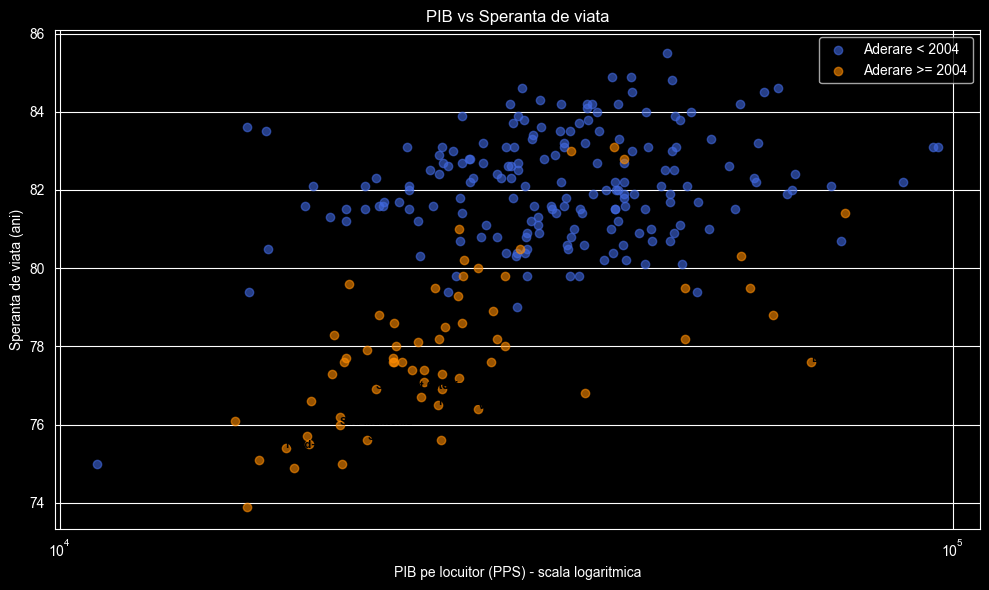

In [73]:
plt.figure(figsize=(10, 6))

vechi = tabel2[tabel2["AnAderare"] < 2004]
noi = tabel2[tabel2["AnAderare"] >= 2004]

plt.scatter(vechi["PIB"], vechi["SperantaViata"], color="royalblue", alpha=0.6, label="Aderare < 2004")
plt.scatter(noi["PIB"], noi["SperantaViata"], color="darkorange", alpha=0.6, label="Aderare >= 2004")

# etichetam regiunile din Romania
ro = tabel2[tabel2["Tara"] == "Romania"]
for cod, rand in ro.iterrows():
    plt.annotate(rand["Denumire"], (rand["PIB"], rand["SperantaViata"]), fontsize=8, color="black", weight="bold")

plt.xscale("log")
plt.xlabel("PIB pe locuitor (PPS) - scala logaritmica")
plt.ylabel("Speranta de viata (ani)")
plt.title("PIB vs Speranta de viata")
plt.legend()
plt.tight_layout()
plt.savefig("./data_out/Cerinta10a.png", dpi=200)
plt.show()

**Interpretare:** Se observa ca la niveluri mici de PIB, orice ban in plus creste spreanta de viata, dar dupa un anumit nivel, graficul se opreste. In plus, tarile din Vest sunt in partea dreapta, sus, deoarece sunt mai bogate. Tarile care au aderat inainte de 2004 au cea mai mare speranta de viata.

**b)** *Cerinta10b.png*: boxplot cu distribuția PIB-ului regional pe țări, cu țările ordonate după mediană. Trasați o linie orizontală la pragul de 75% din media UE (cerința 6).

**Interpretare:**

**c)** *Cerinta10c.png*: heatmap al matricei $R$ de la cerința 7, cu numele variabilelor pe axe, valorile scrise în celule și o legendă a culorilor.

**Interpretare:**

### Concluzii (aprox. 150 de cuvinte)
*Ce diferențiază regiunile bogate de celelalte?* Folosiți rezultatele de la cerințele 3-10: diferențe, coeziune, corelații, grafice.